# Notebook 03 — Scheduler Experiments and Results

**Project:** CAMP — Calibration-Aware ML-Predictive Scheduling for Single-GPU LLM Inference  
**Backend:** Qwen2.5-1.5B-Instruct served by vLLM  
**GPU:** Google Colab Tesla T4 (or another compatible Colab GPU)

This notebook runs the **same benchmark requests** through four policies:

1. **FIFO:** forward requests to vLLM immediately in arrival order; vLLM manages its internal queue.
2. **Fixed-K:** an external FIFO queue with a fixed limit of `K=2` submitted requests.
3. **Heuristic Adaptive:** selects queued requests using prompt/output-token cost, waiting-time aging, and a shared adaptive concurrency controller.
4. **CAMP ML-Predictive:** uses the trained Random Forest latency predictor, its calibration residual margin, the same aging rule, and the same adaptive concurrency controller.

It prints generated responses and measured results, then saves CSV files and plots. **No dashboard or GUI is used.**

> **Important:** Notebook 01 currently creates a small pilot benchmark (12 requests per workload type). The results from this notebook are a pipeline demonstration, not publication-grade evidence. For a paper, increase trace size, use multiple independent trace seeds/repetitions, and repeat the full comparison under the same GPU/model configuration.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 0. Files needed from Notebooks 01 and 02

Upload these four downloaded files when prompted:

- `benchmark_traces.csv` — independent test requests from Notebook 01
- `latency_dataset.csv` — measured request data from Notebook 01 (used to define and report a common pilot engine-latency SLO)
- `camp_latency_predictor.joblib` — selected trained predictor from Notebook 02
- `model_metadata.json` — predictor feature list and calibration margin from Notebook 02

The files must come from the **same run** of Notebooks 01 and 02. The model and metadata must match. Do not use the training latency dataset as the scheduler's benchmark trace.

In [2]:
# Install only lightweight client/analysis packages if needed.
# Do not reinstall vLLM or upgrade PyTorch in this notebook.
%pip -q install openai joblib pandas numpy matplotlib transformers scikit-learn==1.9.1

In [3]:
!nvidia-smi

Tue Nov 24 13:45:15 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   49C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [4]:
import importlib.util, subprocess, sys

if importlib.util.find_spec("vllm") is None:
    print("Installing vLLM for CUDA 13.0. This may take several minutes...")
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q", "vllm",
        "--extra-index-url", "https://download.pytorch.org/whl/cu130"
    ])
    print("vLLM installation finished. Restart the Colab runtime, then rerun this notebook.")
else:
    print("vLLM is already installed; skipping installation.")

missing = [p for p in ["openai", "transformers", "pandas", "requests"]
           if importlib.util.find_spec(p) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
    print("Installed:", ", ".join(missing))
else:
    print("Client/data packages are already installed.")

Installing vLLM for CUDA 13.0. This may take several minutes...
vLLM installation finished. Restart the Colab runtime, then rerun this notebook.
Client/data packages are already installed.


In [5]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU memory (GiB):", round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2))

PyTorch: 2.14.0+cu130
CUDA available: True
GPU: Tesla T4
GPU memory (GiB): 14.56


In [6]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.14.0+cu130
CUDA available: True
GPU: Tesla T4


In [7]:
import asyncio
import json
import math
import os
import shutil
import subprocess
import threading
import time
import warnings
from collections import deque
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import sklearn
from joblib import load
from openai import AsyncOpenAI
from transformers import AutoTokenizer
from IPython.display import display

SEED = 42
np.random.seed(SEED)

print("Python:", os.sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("scikit-learn:", sklearn.__version__)
print("CUDA available:", torch.cuda.is_available())
if not torch.cuda.is_available():
    raise RuntimeError("A CUDA GPU is required for the vLLM scheduler experiments. Select a GPU runtime in Colab.")
print("GPU:", torch.cuda.get_device_name(0))
print("GPU memory (GiB):", round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2))

Python: 3.13.16
PyTorch: 2.14.0+cu130
scikit-learn: 1.9.1
CUDA available: True
GPU: Tesla T4
GPU memory (GiB): 14.56


In [9]:
# Search Colab storage and the project folder in mounted Google Drive.
from pathlib import Path
from google.colab import files

PROJECT_DIR = Path("/content/drive/MyDrive/GEN_AI LAB Assignment")
SEARCH_DIRS = [Path("/content"), PROJECT_DIR]

REQUIRED_PATTERNS = {
    "benchmark": "benchmark_traces*.csv",
    "dataset": "latency_dataset*.csv",
    "model": "camp_latency_predictor*.joblib",
    "metadata": "model_metadata*.json",
}

def find_latest(pattern):
    matches = [
        path
        for directory in SEARCH_DIRS
        if directory.exists()
        for path in directory.glob(pattern)
        if path.is_file()
    ]
    return max(matches, key=lambda p: p.stat().st_mtime) if matches else None

missing = [name for name, pattern in REQUIRED_PATTERNS.items() if find_latest(pattern) is None]
if missing:
    print(f"Missing files: {missing}. Select those files from your computer to upload.")
    files.upload()

paths = {name: find_latest(pattern) for name, pattern in REQUIRED_PATTERNS.items()}
missing_after = [name for name, path in paths.items() if path is None]
if missing_after:
    raise FileNotFoundError(
        f"Still missing {missing_after}. Upload them to /content or "
        f"place them in {PROJECT_DIR}, then rerun this cell."
    )

for name, path in paths.items():
    print(f"{name:10s}: {path}")

benchmark : /content/benchmark_traces.csv
dataset   : /content/drive/MyDrive/GEN_AI LAB Assignment/latency_dataset.csv
model     : /content/camp_latency_predictor.joblib
metadata  : /content/drive/MyDrive/GEN_AI LAB Assignment/model_metadata.json


In [10]:
# Load traces, collected data, model, and its metadata.
benchmark_df = pd.read_csv(paths["benchmark"])
latency_df = pd.read_csv(paths["dataset"])
model_metadata = json.loads(paths["metadata"].read_text())
predictor = load(paths["model"])

BENCHMARK_REQUIRED = {
    "request_id", "workload_type", "arrival_offset_s", "prompt_text",
    "prompt_tokens", "max_output_tokens"
}
missing_cols = BENCHMARK_REQUIRED - set(benchmark_df.columns)
if missing_cols:
    raise ValueError(f"benchmark_traces.csv is missing columns: {sorted(missing_cols)}")

if "engine_latency_s" not in latency_df or "status" not in latency_df:
    raise ValueError("latency_dataset.csv must contain engine_latency_s and status columns.")

FEATURES = model_metadata.get("features", [])
if not FEATURES:
    raise ValueError("model_metadata.json has no predictor feature list.")
CALIBRATION_MARGIN_S = float(model_metadata.get("calibration_residual_margin_s", 0.0))
SELECTED_MODEL_NAME = model_metadata.get("selected_model", "Unknown model")

print("Predictor selected in Notebook 02:", SELECTED_MODEL_NAME)
print("Predictor features:", FEATURES)
print("Calibration residual margin (s):", round(CALIBRATION_MARGIN_S, 4))
print("Benchmark shape:", benchmark_df.shape)
print("Training-data shape:", latency_df.shape)
display(benchmark_df.groupby("workload_type").agg(
    requests=("request_id", "count"),
    mean_prompt_tokens=("prompt_tokens", "mean"),
    mean_max_output_tokens=("max_output_tokens", "mean")
).round(2))

# Check for a likely model/package version mismatch before loading predictions.
trained_sklearn = model_metadata.get("scikit_learn_version")
if trained_sklearn and trained_sklearn != sklearn.__version__:
    warnings.warn(
        f"The predictor was trained with scikit-learn {trained_sklearn}, "
        f"but this runtime has {sklearn.__version__}. Joblib/sklearn compatibility can vary. "
        "If prediction fails, use the same scikit-learn version as Notebook 02."
    )

Predictor selected in Notebook 02: Random Forest
Predictor features: ['prompt_tokens', 'max_output_tokens', 'arrival_rate_5s_rps', 'queue_depth_at_admission', 'active_requests_at_admission', 'concurrency_limit', 'gpu_utilization_pct', 'gpu_memory_used_mib']
Calibration residual margin (s): 0.2434
Benchmark shape: (36, 6)
Training-data shape: (180, 21)


,requests,mean_prompt_tokens,mean_max_output_tokens
workload_type,,,
bursty,12,2.0,74.67
mixed,12,2.0,72.00
steady,12,2.0,66.67


## 1. Start or reuse the vLLM server

This cell reuses the Notebook 01 server if it is still running. If the Colab runtime was restarted, it starts vLLM again using the same model and conservative T4 settings.

In [11]:
MODEL_ID = "Qwen/Qwen2.5-1.5B-Instruct"
SERVER_HOST = "127.0.0.1"
SERVER_PORT = 8000
BASE_URL = f"http://{SERVER_HOST}:{SERVER_PORT}/v1"
SERVER_LOG = "/content/vllm_notebook03.log"

import requests

def server_is_ready():
    try:
        return requests.get(f"http://{SERVER_HOST}:{SERVER_PORT}/health", timeout=3).status_code == 200
    except Exception:
        return False

server_process = None
server_log_handle = None
if not server_is_ready():
    executable = shutil.which("vllm")
    if not executable:
        raise RuntimeError(
            "The vLLM command is unavailable. Return to Notebook 01's installation cell, "
            "install vLLM in this runtime, restart if requested, and rerun this notebook."
        )
    command = [
        executable, "serve", MODEL_ID,
        "--dtype", "half",
        "--max-model-len", "2048",
        "--max-num-seqs", "4",
        "--gpu-memory-utilization", "0.85",
        "--host", SERVER_HOST,
        "--port", str(SERVER_PORT)
    ]
    server_log_handle = open(SERVER_LOG, "w")
    server_process = subprocess.Popen(command, stdout=server_log_handle, stderr=subprocess.STDOUT)
    print("Starting vLLM. Waiting for model loading...")
    deadline = time.time() + 900
    while time.time() < deadline and server_process.poll() is None:
        if server_is_ready():
            break
        time.sleep(5)

if not server_is_ready():
    if Path(SERVER_LOG).exists():
        print("\n".join(Path(SERVER_LOG).read_text(errors="ignore").splitlines()[-80:]))
    raise RuntimeError("vLLM did not become ready. Review the log before continuing.")

print("vLLM is ready at:", BASE_URL)

Starting vLLM. Waiting for model loading...
vLLM is ready at: http://127.0.0.1:8000/v1


In [12]:
client = AsyncOpenAI(base_url=BASE_URL, api_key="EMPTY", timeout=600.0, max_retries=0)
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, use_fast=True)

# AsyncOpenAI model listing must be awaited in Colab.
model_list = await client.models.list()
available_model_ids = [item.id for item in model_list.data]
print("Available model IDs:", available_model_ids)
if MODEL_ID not in available_model_ids:
    raise RuntimeError(f"Expected model {MODEL_ID} is not exposed by vLLM. Check server logs.")

# Warm-up request: excluded from all benchmark measurements.
warmup = await client.chat.completions.create(
    model=MODEL_ID,
    messages=[{"role": "user", "content": "Reply with the word READY."}],
    max_tokens=8,
    temperature=0
)
print("Warm-up response:", warmup.choices[0].message.content)

Available model IDs: ['Qwen/Qwen2.5-1.5B-Instruct']
Warm-up response: READY


## 2. Common experiment settings

All four policies use the same prompts, requested output limits, arrival offsets, Qwen model, vLLM server, and GPU. The fixed baseline uses `K=2`; adaptive policies begin at `K=2` and may adjust between 1 and 4. The vLLM backend is configured with `max-num-seqs=4`.

The engine-latency SLO below is defined from the **90th percentile of successful Notebook 01 pilot measurements**. This is a transparent pilot threshold, not an externally supplied production SLO. Report its value in any paper or presentation.

In [13]:
FIXED_K = 2
MIN_ADAPTIVE_K = 1
INITIAL_ADAPTIVE_K = 2
MAX_ADAPTIVE_K = 4
AGING_TAU_S = 5.0
MAX_WAIT_PRIORITY_S = 15.0
HEURISTIC_OUTPUT_WEIGHT = 1.0

successful_training = latency_df[
    latency_df["status"].astype(str).str.lower().eq("completed")
].copy()
successful_training["engine_latency_s"] = pd.to_numeric(
    successful_training["engine_latency_s"], errors="coerce"
)
successful_training = successful_training[
    np.isfinite(successful_training["engine_latency_s"])
    & (successful_training["engine_latency_s"] > 0)
]
if len(successful_training) < 5:
    raise ValueError("Too few successful collection rows to define the pilot SLO.")

SLO_TARGET_S = float(successful_training["engine_latency_s"].quantile(0.90))
print("Fixed-K:", FIXED_K)
print("Adaptive concurrency range:", MIN_ADAPTIVE_K, "to", MAX_ADAPTIVE_K)
print("Aging tau (s):", AGING_TAU_S)
print("Pilot engine-latency SLO (90th percentile, seconds):", round(SLO_TARGET_S, 4))
print("Benchmark requests:", len(benchmark_df))
print("Workloads:", sorted(benchmark_df["workload_type"].astype(str).unique()))

if len(benchmark_df) < 100:
    warnings.warn(
        "This benchmark trace has fewer than 100 requests. Treat policy comparisons as a pilot; "
        "do not claim statistically reliable improvements from this run."
    )

Fixed-K: 2
Adaptive concurrency range: 1 to 4
Aging tau (s): 5.0
Pilot engine-latency SLO (90th percentile, seconds): 1.6765
Benchmark requests: 36
Workloads: ['bursty', 'mixed', 'steady']


/tmp/ipykernel_477/415200926.py:31: UserWarning: This benchmark trace has fewer than 100 requests. Treat policy comparisons as a pilot; do not claim statistically reliable improvements from this run.
  warnings.warn(


In [14]:
# Background GPU telemetry sampler. Samples are read at request-admission decisions.
_gpu_stop = threading.Event()
_gpu_lock = threading.Lock()
_gpu_samples = []

def _sample_gpu_loop():
    while not _gpu_stop.is_set():
        try:
            output = subprocess.check_output(
                ["nvidia-smi", "--query-gpu=utilization.gpu,memory.used,memory.total",
                 "--format=csv,noheader,nounits"],
                text=True, stderr=subprocess.DEVNULL, timeout=5
            )
            fields = [x.strip() for x in output.strip().split(",")]
            sample = {
                "gpu_utilization_pct": float(fields[0]),
                "gpu_memory_used_mib": float(fields[1]),
                "gpu_memory_total_mib": float(fields[2]),
                "sampled_at": time.perf_counter()
            }
            with _gpu_lock:
                _gpu_samples.append(sample)
                if len(_gpu_samples) > 5000:
                    del _gpu_samples[:1000]
        except Exception:
            pass
        _gpu_stop.wait(1.0)

_gpu_thread = threading.Thread(target=_sample_gpu_loop, daemon=True)
_gpu_thread.start()
time.sleep(2)

def latest_gpu_sample():
    with _gpu_lock:
        if _gpu_samples:
            return dict(_gpu_samples[-1])
    return {
        "gpu_utilization_pct": np.nan,
        "gpu_memory_used_mib": np.nan,
        "gpu_memory_total_mib": np.nan,
        "sampled_at": np.nan
    }

print("Initial GPU telemetry:", latest_gpu_sample())

Initial GPU telemetry: {'gpu_utilization_pct': 0.0, 'gpu_memory_used_mib': 12325.0, 'gpu_memory_total_mib': 15360.0, 'sampled_at': 766.872273443}


## 3. Request execution and feature construction

The predictor receives only information available at the admission decision. The target it predicts is the same target used in Notebook 02: time from external submission to final streamed response (`engine_latency_s`). It is an endpoint-observed engine interval, not a measurement of pure GPU compute time.

In [15]:
def arrival_rate_5s(arrival_times, now, run_start):
    recent_count = sum(t >= now - 5.0 for t in arrival_times)
    window = min(5.0, max(0.2, now - run_start))
    return float(recent_count / window)


def build_predictor_features(spec, queue_depth, active_requests, concurrency_limit,
                             arrival_times, now, run_start, gpu):
    values = {
        "prompt_tokens": float(spec["prompt_tokens"]),
        "max_output_tokens": float(spec["max_output_tokens"]),
        "arrival_rate_5s_rps": arrival_rate_5s(arrival_times, now, run_start),
        "queue_depth_at_admission": float(queue_depth),
        "active_requests_at_admission": float(active_requests),
        "concurrency_limit": float(concurrency_limit),
        "gpu_utilization_pct": gpu.get("gpu_utilization_pct", np.nan),
        "gpu_memory_used_mib": gpu.get("gpu_memory_used_mib", np.nan),
    }
    # Use precisely the feature names/order recorded with the trained pipeline.
    return pd.DataFrame([[values.get(name, np.nan) for name in FEATURES]], columns=FEATURES)


def predict_latency_and_upper(feature_frame):
    prediction = float(np.asarray(predictor.predict(feature_frame)).reshape(-1)[0])
    prediction = max(0.0, prediction)
    upper = prediction + max(0.0, CALIBRATION_MARGIN_S)
    return prediction, upper


async def execute_request(spec, enqueue_at, run_start, arrival_times, state,
                          queue_depth, concurrency_limit, policy_name,
                          predicted_latency=np.nan, calibrated_upper=np.nan,
                          predictor_fallback=False):
    admission_at = time.perf_counter()
    active_at_admission = state["active"]
    state["active"] += 1
    gpu = latest_gpu_sample()
    feature_frame = build_predictor_features(
        spec, queue_depth, active_at_admission, concurrency_limit,
        arrival_times, admission_at, run_start, gpu
    )
    output_text = ""
    first_token_at = None
    status = "completed"
    error = ""
    completion_at = admission_at

    try:
        stream = await client.chat.completions.create(
            model=MODEL_ID,
            messages=[{"role": "user", "content": str(spec["prompt_text"])}],
            max_tokens=int(spec["max_output_tokens"]),
            temperature=0,
            stream=True
        )
        async for chunk in stream:
            if not chunk.choices:
                continue
            piece = chunk.choices[0].delta.content
            if piece:
                if first_token_at is None:
                    first_token_at = time.perf_counter()
                output_text += piece
        completion_at = time.perf_counter()
    except Exception as exc:
        completion_at = time.perf_counter()
        status = "failed"
        error = f"{type(exc).__name__}: {str(exc)[:250]}"
    finally:
        state["active"] = max(0, state["active"] - 1)

    output_tokens = len(tokenizer.encode(output_text, add_special_tokens=False)) if output_text else 0
    return {
        "request_id": spec["request_id"],
        "workload_type": spec["workload_type"],
        "policy": policy_name,
        "arrival_offset_s": float(spec["arrival_offset_s"]),
        "prompt_tokens": int(spec["prompt_tokens"]),
        "max_output_tokens": int(spec["max_output_tokens"]),
        "actual_output_tokens": int(output_tokens),
        "queue_wait_s": max(0.0, admission_at - enqueue_at),
        "engine_latency_s": max(0.0, completion_at - admission_at),
        "end_to_end_s": max(0.0, completion_at - enqueue_at),
        "ttft_engine_s": (first_token_at - admission_at) if first_token_at else np.nan,
        "arrival_rate_5s_rps": arrival_rate_5s(arrival_times, admission_at, run_start),
        "queue_depth_at_admission": int(queue_depth),
        "active_requests_at_admission": int(active_at_admission),
        "concurrency_limit_at_admission": int(concurrency_limit),
        "gpu_utilization_pct": gpu.get("gpu_utilization_pct", np.nan),
        "gpu_memory_used_mib": gpu.get("gpu_memory_used_mib", np.nan),
        "predicted_engine_latency_s": predicted_latency,
        "calibrated_upper_latency_s": calibrated_upper,
        "predictor_fallback": bool(predictor_fallback),
        "status": status,
        "error": error,
        "output_preview": output_text[:240],
        "enqueue_perf": enqueue_at,
        "completion_perf": completion_at,
    }

## 4. Implement the four scheduling policies

- **FIFO:** requests are submitted to vLLM as they arrive; the backend manages its own queue.
- **Fixed-K:** a FIFO queue is drained by exactly `K=2` external workers.
- **Heuristic Adaptive:** queued requests are ranked by `prompt_tokens + output_weight × max_output_tokens`, with aging.
- **CAMP:** queued requests are ranked by the calibrated upper latency estimate (`prediction + calibration residual margin`), with the same aging rule.

The two adaptive policies share the same concurrency controller. It adjusts the external limit from recent measured engine latency and GPU memory telemetry. This keeps the main comparison focused on the **heuristic size estimate versus the calibrated ML estimate**.

In [16]:
async def wait_until(start_time, offset_s):
    delay = start_time + float(offset_s) - time.perf_counter()
    if delay > 0:
        await asyncio.sleep(delay)


def records_for_workload(workload_type):
    part = benchmark_df[benchmark_df["workload_type"].astype(str).eq(str(workload_type))].copy()
    part = part.sort_values(["arrival_offset_s", "request_id"]).reset_index(drop=True)
    if part.empty:
        raise ValueError(f"No requests found for workload {workload_type}")
    return part.to_dict("records")


async def run_fifo(specs, workload_type):
    run_start = time.perf_counter()
    arrival_times = []
    state = {"active": 0}
    tasks = []

    async def producer():
        for spec in specs:
            await wait_until(run_start, spec["arrival_offset_s"])
            enqueue_at = time.perf_counter()
            arrival_times.append(enqueue_at)
            # Immediate dispatch in arrival order; vLLM manages its internal queue.
            tasks.append(asyncio.create_task(execute_request(
                spec, enqueue_at, run_start, arrival_times, state,
                queue_depth=0, concurrency_limit=MAX_ADAPTIVE_K,
                policy_name="FIFO"
            )))

    await producer()
    results = await asyncio.gather(*tasks)
    return results


async def run_fixed_k(specs, workload_type):
    run_start = time.perf_counter()
    arrival_times = []
    state = {"active": 0}
    queue = asyncio.Queue()
    results = []

    async def producer():
        for spec in specs:
            await wait_until(run_start, spec["arrival_offset_s"])
            enqueue_at = time.perf_counter()
            arrival_times.append(enqueue_at)
            await queue.put((spec, enqueue_at))
        for _ in range(FIXED_K):
            await queue.put(None)

    async def worker():
        while True:
            item = await queue.get()
            if item is None:
                queue.task_done()
                return
            spec, enqueue_at = item
            result = await execute_request(
                spec, enqueue_at, run_start, arrival_times, state,
                queue_depth=queue.qsize(), concurrency_limit=FIXED_K,
                policy_name="Fixed-K"
            )
            results.append(result)
            queue.task_done()

    workers = [asyncio.create_task(worker()) for _ in range(FIXED_K)]
    producer_task = asyncio.create_task(producer())
    await producer_task
    await queue.join()
    await asyncio.gather(*workers)
    return results


def age_adjusted_priority(cost, wait_s):
    # After the maximum-wait threshold, explicitly elevate the request.
    if wait_s >= MAX_WAIT_PRIORITY_S:
        return -1_000_000.0 - wait_s
    return float(cost) / (1.0 + max(0.0, wait_s) / AGING_TAU_S)


def update_adaptive_limit(current_limit, completed_engine_latencies):
    # Shared controller for both adaptive policies; evaluated every 3 completions.
    if len(completed_engine_latencies) < 3 or len(completed_engine_latencies) % 3 != 0:
        return current_limit
    recent = np.asarray(completed_engine_latencies[-5:], dtype=float)
    recent_p75 = float(np.quantile(recent, 0.75))
    gpu = latest_gpu_sample()
    memory_ratio = (
        gpu["gpu_memory_used_mib"] / gpu["gpu_memory_total_mib"]
        if np.isfinite(gpu["gpu_memory_used_mib"]) and gpu["gpu_memory_total_mib"] > 0
        else 0.0
    )
    if recent_p75 > 1.05 * SLO_TARGET_S or memory_ratio > 0.92:
        return max(MIN_ADAPTIVE_K, current_limit - 1)
    if recent_p75 < 0.75 * SLO_TARGET_S and memory_ratio < 0.85:
        return min(MAX_ADAPTIVE_K, current_limit + 1)
    return current_limit


async def run_adaptive(specs, workload_type, use_predictor):
    policy_name = "CAMP ML-Predictive" if use_predictor else "Heuristic Adaptive"
    run_start = time.perf_counter()
    arrival_times = []
    pending = []
    completed_results = []
    active_tasks = set()
    state = {"active": 0}
    effective_limit = INITIAL_ADAPTIVE_K
    done_producing = False

    async def producer():
        nonlocal done_producing
        for spec in specs:
            await wait_until(run_start, spec["arrival_offset_s"])
            enqueue_at = time.perf_counter()
            arrival_times.append(enqueue_at)
            pending.append({"spec": spec, "enqueue_at": enqueue_at})
        done_producing = True

    producer_task = asyncio.create_task(producer())
    recent_engine_latencies = []

    while (not done_producing) or pending or active_tasks:
        # Fill free external slots using the chosen policy's priority.
        while pending and len(active_tasks) < effective_limit:
            now = time.perf_counter()
            gpu = latest_gpu_sample()
            scored = []
            for item in pending:
                spec = item["spec"]
                wait_s = now - item["enqueue_at"]
                if use_predictor:
                    feature_frame = build_predictor_features(
                        spec, queue_depth=len(pending), active_requests=len(active_tasks),
                        concurrency_limit=effective_limit, arrival_times=arrival_times,
                        now=now, run_start=run_start, gpu=gpu
                    )
                    try:
                        pred, upper = predict_latency_and_upper(feature_frame)
                        item["predicted_engine_latency_s"] = pred
                        item["calibrated_upper_latency_s"] = upper
                        item["predictor_fallback"] = False
                    except Exception as exc:
                        # Conservative, explicit fallback to the heuristic estimate.
                        fallback_cost = float(spec["prompt_tokens"]) + HEURISTIC_OUTPUT_WEIGHT * float(spec["max_output_tokens"])
                        item["predicted_engine_latency_s"] = np.nan
                        item["calibrated_upper_latency_s"] = np.nan
                        item["predictor_fallback"] = True
                    if item["predictor_fallback"]:
                        cost = fallback_cost
                    else:
                        cost = item["calibrated_upper_latency_s"]
                else:
                    cost = float(spec["prompt_tokens"]) + HEURISTIC_OUTPUT_WEIGHT * float(spec["max_output_tokens"])
                    item["predicted_engine_latency_s"] = np.nan
                    item["calibrated_upper_latency_s"] = np.nan
                    item["predictor_fallback"] = False
                scored.append(age_adjusted_priority(cost, wait_s))

            chosen_index = int(np.argmin(scored))
            item = pending.pop(chosen_index)
            spec = item["spec"]
            task = asyncio.create_task(execute_request(
                spec, item["enqueue_at"], run_start, arrival_times, state,
                queue_depth=len(pending), concurrency_limit=effective_limit,
                policy_name=policy_name,
                predicted_latency=item.get("predicted_engine_latency_s", np.nan),
                calibrated_upper=item.get("calibrated_upper_latency_s", np.nan),
                predictor_fallback=item.get("predictor_fallback", False)
            ))
            active_tasks.add(task)

        if active_tasks:
            done, still_running = await asyncio.wait(
                active_tasks, timeout=0.05, return_when=asyncio.FIRST_COMPLETED
            )
            active_tasks = set(still_running)
            for task in done:
                result = task.result()
                completed_results.append(result)
                if result["status"] == "completed":
                    recent_engine_latencies.append(float(result["engine_latency_s"]))
                    effective_limit = update_adaptive_limit(effective_limit, recent_engine_latencies)
        else:
            await asyncio.sleep(0.01)

    await producer_task
    return completed_results

print("Four policy implementations are ready.")

Four policy implementations are ready.


## 5. Run the controlled comparison

The same per-workload trace is replayed for each policy. Policy order is rotated between workload types to reduce systematic order effects. Each run drains all submitted requests before the next policy starts.

In [17]:
POLICY_RUNNERS = [
    ("FIFO", run_fifo),
    ("Fixed-K", run_fixed_k),
    ("Heuristic Adaptive", lambda specs, workload: run_adaptive(specs, workload, use_predictor=False)),
    ("CAMP ML-Predictive", lambda specs, workload: run_adaptive(specs, workload, use_predictor=True)),
]

all_result_rows = []
workload_types = sorted(benchmark_df["workload_type"].astype(str).unique())

for workload_index, workload_type in enumerate(workload_types):
    specs = records_for_workload(workload_type)
    # Rotate order for each workload type; requests and settings remain identical.
    order = POLICY_RUNNERS[workload_index:] + POLICY_RUNNERS[:workload_index]
    print(f"\n{'='*72}\nWORKLOAD: {workload_type} | REQUESTS: {len(specs)}\n{'='*72}")
    for policy_name, runner in order:
        print(f"Running {policy_name} ...", end=" ", flush=True)
        start_wall = time.perf_counter()
        result_rows = await runner(specs, workload_type)
        elapsed_wall = time.perf_counter() - start_wall
        all_result_rows.extend(result_rows)
        successes = sum(row["status"] == "completed" for row in result_rows)
        print(f"done — {successes}/{len(result_rows)} completed in {elapsed_wall:.1f}s")
        await asyncio.sleep(2.0)  # short cooldown between policy runs

results_df = pd.DataFrame(all_result_rows)
if results_df.empty:
    raise RuntimeError("No scheduler results were produced.")
print("\nTotal request-policy observations:", len(results_df))
display(results_df.groupby(["workload_type", "policy", "status"]).size().rename("count").to_frame())


WORKLOAD: bursty | REQUESTS: 12
Running FIFO ... done — 12/12 completed in 7.6s
Running Fixed-K ... done — 12/12 completed in 7.6s
Running Heuristic Adaptive ... done — 12/12 completed in 7.6s
Running CAMP ML-Predictive ... done — 12/12 completed in 9.3s

WORKLOAD: mixed | REQUESTS: 12
Running Fixed-K ... done — 12/12 completed in 7.2s
Running Heuristic Adaptive ... done — 12/12 completed in 5.2s
Running CAMP ML-Predictive ... done — 12/12 completed in 8.5s
Running FIFO ... done — 12/12 completed in 5.2s

WORKLOAD: steady | REQUESTS: 12
Running Heuristic Adaptive ... done — 12/12 completed in 7.3s
Running CAMP ML-Predictive ... done — 12/12 completed in 7.3s
Running FIFO ... done — 12/12 completed in 7.2s
Running Fixed-K ... done — 12/12 completed in 7.2s

Total request-policy observations: 144


count
workload_type policy             status          
bursty        CAMP ML-Predictive completed     12
              FIFO               completed     12
              Fixed-K            completed     12
              Heuristic Adaptive completed     12
mixed         CAMP ML-Predictive completed     12
              FIFO               completed     12
              Fixed-K            completed     12
              Heuristic Adaptive completed     12
steady        CAMP ML-Predictive completed     12
              FIFO               completed     12
              Fixed-K            completed     12
              Heuristic Adaptive completed     12

## 6. Calculate metrics

Metric boundaries match the definitions used in Notebook 01 and the literature review:

- `queue_wait_s`: external waiting time before the request is sent to vLLM.
- `engine_latency_s`: request submission to final streamed response; includes vLLM-side queueing, prefill, decode, and response streaming.
- `end_to_end_s`: external queue entry to final streamed response.
- `goodput`: requests completing within the shared pilot engine-latency SLO, divided by experiment duration.

Failed requests are counted separately and are not silently dropped from the success-rate calculation.

In [18]:
def safe_quantile(series, q):
    values = pd.to_numeric(series, errors="coerce").dropna()
    return float(values.quantile(q)) if len(values) else np.nan

summary_rows = []
for (workload, policy), group in results_df.groupby(["workload_type", "policy"], sort=False):
    successful = group[group["status"].eq("completed")].copy()
    submitted = len(group)
    completed = len(successful)
    failed = submitted - completed
    start_perf = float(group["enqueue_perf"].min())
    finish_perf = float(group["completion_perf"].max())
    duration_s = max(1e-9, finish_perf - start_perf)
    on_time = int((successful["engine_latency_s"] <= SLO_TARGET_S).sum()) if completed else 0

    summary_rows.append({
        "workload_type": workload,
        "policy": policy,
        "submitted": submitted,
        "completed": completed,
        "failed": failed,
        "success_rate": completed / submitted if submitted else np.nan,
        "duration_s": duration_s,
        "mean_queue_wait_s": successful["queue_wait_s"].mean() if completed else np.nan,
        "p95_queue_wait_s": safe_quantile(successful["queue_wait_s"], 0.95),
        "max_queue_wait_s": successful["queue_wait_s"].max() if completed else np.nan,
        "mean_engine_latency_s": successful["engine_latency_s"].mean() if completed else np.nan,
        "p50_engine_latency_s": safe_quantile(successful["engine_latency_s"], 0.50),
        "p95_engine_latency_s": safe_quantile(successful["engine_latency_s"], 0.95),
        "p99_engine_latency_s": safe_quantile(successful["engine_latency_s"], 0.99),
        "p95_end_to_end_s": safe_quantile(successful["end_to_end_s"], 0.95),
        "p50_ttft_engine_s": safe_quantile(successful["ttft_engine_s"], 0.50),
        "request_throughput_rps": completed / duration_s,
        "output_token_throughput_tps": successful["actual_output_tokens"].sum() / duration_s if completed else 0.0,
        "goodput_rps": on_time / duration_s,
        "engine_slo_target_s": SLO_TARGET_S,
        "mean_gpu_utilization_pct": successful["gpu_utilization_pct"].mean() if completed else np.nan,
        "max_gpu_memory_used_mib": successful["gpu_memory_used_mib"].max() if completed else np.nan,
        "predictor_fallback_count": int(group["predictor_fallback"].sum()),
    })

summary_df = pd.DataFrame(summary_rows)
print("Scheduler summary (times in seconds; throughput in requests/tokens per second):")
display(summary_df.sort_values(["workload_type", "policy"]).round(4))

Scheduler summary (times in seconds; throughput in requests/tokens per second):


,workload_type,policy,submitted,completed,failed,success_rate,duration_s,mean_queue_wait_s,p95_queue_wait_s,max_queue_wait_s,...,p99_engine_latency_s,p95_end_to_end_s,p50_ttft_engine_s,request_throughput_rps,output_token_throughput_tps,goodput_rps,engine_slo_target_s,mean_gpu_utilization_pct,max_gpu_memory_used_mib,predictor_fallback_count
3,bursty,CAMP ML-Predictive,12,12,0,1.0,9.2841,1.6916,3.2033,3.5468,...,1.8993,4.5761,0.1097,1.2925,88.1080,1.1848,1.6765,75.0000,12433.0,0
0,bursty,FIFO,12,12,0,1.0,7.5635,0.0001,0.0001,0.0001,...,2.0819,2.0076,0.2174,1.5866,108.1516,1.3221,1.6765,0.0000,12429.0,0
1,bursty,Fixed-K,12,12,0,1.0,7.5951,0.6825,1.8744,1.9288,...,1.6173,2.9100,0.0532,1.5800,107.5688,1.5800,1.6765,77.1667,12433.0,0
2,bursty,Heuristic Adaptive,12,12,0,1.0,7.6135,0.5099,1.4767,1.5340,...,1.5970,2.5398,0.0593,1.5761,107.0464,1.5761,1.6765,41.6667,12433.0,0
6,mixed,CAMP ML-Predictive,12,12,0,1.0,8.4619,1.7708,3.5508,3.7892,...,2.0350,5.0780,0.0788,1.4181,95.4865,1.2999,1.6765,56.6667,12433.0,0
7,mixed,FIFO,12,12,0,1.0,5.1851,0.0000,0.0001,0.0001,...,1.6204,1.5857,0.0599,2.3143,155.8309,2.3143,1.6765,82.7500,12433.0,0
4,mixed,Fixed-K,12,12,0,1.0,7.1553,0.9528,2.0913,2.1317,...,1.5814,3.2201,0.0721,1.6771,112.9225,1.6771,1.6765,83.3333,12433.0,0
5,mixed,Heuristic Adaptive,12,12,0,1.0,5.2264,0.2916,0.7570,0.8885,...,1.5788,2.0642,0.0590,2.2960,154.5995,2.2960,1.6765,83.3333,12433.0,0
9,steady,CAMP ML-Predictive,12,12,0,1.0,7.3108,0.1684,0.2801,0.4018,...,1.6032,1.7630,0.0665,1.6414,97.9379,1.6414,1.6765,83.3333,12433.0,0
10,steady,FIFO,12,12,0,1.0,7.1786,0.0000,0.0001,0.0001,...,1.6349,1.4819,0.0692,1.6716,99.7413,1.6716,1.6765,82.3333,12433.0,0


In [19]:
# Evaluate CAMP's point and calibrated-upper predictions against actual engine latency.
camp_rows = results_df[
    results_df["policy"].eq("CAMP ML-Predictive")
    & results_df["status"].eq("completed")
    & results_df["predicted_engine_latency_s"].notna()
].copy()

if len(camp_rows):
    actual = camp_rows["engine_latency_s"].to_numpy(dtype=float)
    point = camp_rows["predicted_engine_latency_s"].to_numpy(dtype=float)
    upper = camp_rows["calibrated_upper_latency_s"].to_numpy(dtype=float)
    predictor_report = pd.DataFrame([{
        "requests": len(camp_rows),
        "MAE_s": float(np.mean(np.abs(actual - point))),
        "RMSE_s": float(np.sqrt(np.mean((actual - point) ** 2))),
        "underprediction_rate": float(np.mean(actual > point)),
        "calibrated_upper_coverage": float(np.mean(actual <= upper)),
        "fallback_count": int(results_df.loc[
            results_df["policy"].eq("CAMP ML-Predictive"), "predictor_fallback"
        ].sum()),
    }])
    print("CAMP prediction quality on scheduler benchmark requests:")
    display(predictor_report.round(4))
else:
    predictor_report = pd.DataFrame()
    print("No valid CAMP predictions were available. Inspect predictor features and fallback counts.")

print("\nFirst response examples (up to one per policy/workload):")
examples = (results_df[results_df["status"].eq("completed")]
            .sort_values("completion_perf")
            .groupby(["workload_type", "policy"], as_index=False)
            .head(1))
for _, row in examples.iterrows():
    print(f"\n[{row['workload_type']} | {row['policy']} | {row['request_id']}]")
    print(row["output_preview"] or "<empty response>")

CAMP prediction quality on scheduler benchmark requests:


,requests,MAE_s,RMSE_s,underprediction_rate,calibrated_upper_coverage,fallback_count
0,36,0.2223,0.3085,0.4722,0.75,0



First response examples (up to one per policy/workload):

[bursty | FIFO | benchmark_bursty_req_0003]
The given text describes various components in an AI system's request handling process, including:

1. **Prefill Phase**: Processes input tokens.
2. **Decode

[bursty | Fixed-K | benchmark_bursty_req_0000]
Large language models in serving systems experience increased latency due to bursts of requests that fill up the queue. This affects subsequent requests negatively. Key metrics like throughput (requests per second), tail latency (latency at

[bursty | Heuristic Adaptive | benchmark_bursty_req_0000]
Large language models in serving systems experience increased latency due to bursts of requests that fill up the queue. This affects subsequent requests negatively. Key metrics like throughput (requests per second), tail latency (latency at

[bursty | CAMP ML-Predictive | benchmark_bursty_req_0003]
The given text describes various components in an AI system's request handling process, inc

## 7. Compare policies and create plots

Interpret the results together: a policy that reduces p95 latency by rejecting or failing requests is not automatically better. Always inspect completion rate, goodput, output-token throughput, and queue waiting time alongside latency.

,workload_type,policy,success_rate,mean_queue_wait_s,p95_engine_latency_s,request_throughput_rps,output_token_throughput_tps,goodput_rps,max_queue_wait_s
3,bursty,CAMP ML-Predictive,1.0,1.6916,1.7646,1.2925,88.1080,1.1848,3.5468
0,bursty,FIFO,1.0,0.0001,2.0076,1.5866,108.1516,1.3221,0.0001
1,bursty,Fixed-K,1.0,0.6825,1.5634,1.5800,107.5688,1.5800,1.9288
2,bursty,Heuristic Adaptive,1.0,0.5099,1.5528,1.5761,107.0464,1.5761,1.5340
6,mixed,CAMP ML-Predictive,1.0,1.7708,1.8508,1.4181,95.4865,1.2999,3.7892
7,mixed,FIFO,1.0,0.0000,1.5857,2.3143,155.8309,2.3143,0.0001
4,mixed,Fixed-K,1.0,0.9528,1.5802,1.6771,112.9225,1.6771,2.1317
5,mixed,Heuristic Adaptive,1.0,0.2916,1.5619,2.2960,154.5995,2.2960,0.8885
9,steady,CAMP ML-Predictive,1.0,0.1684,1.4678,1.6414,97.9379,1.6414,0.4018
10,steady,FIFO,1.0,0.0000,1.4819,1.6716,99.7413,1.6716,0.0001


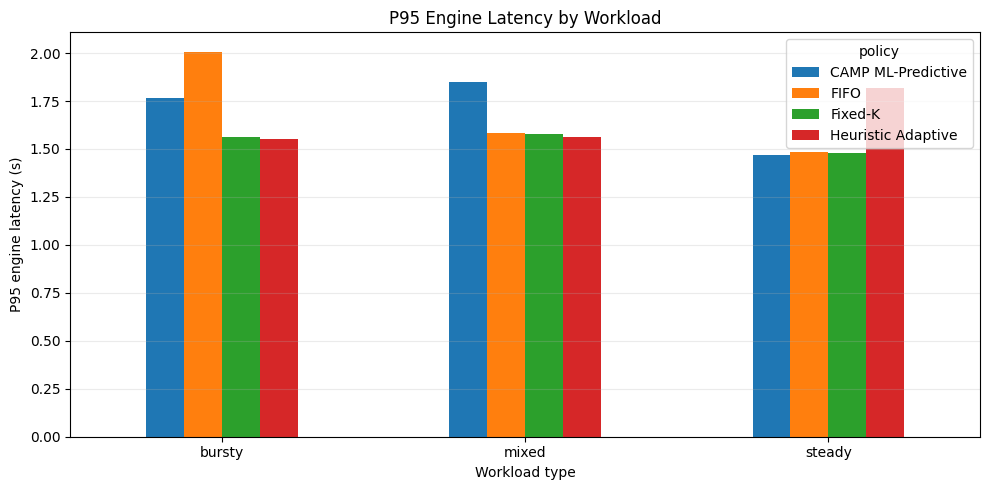

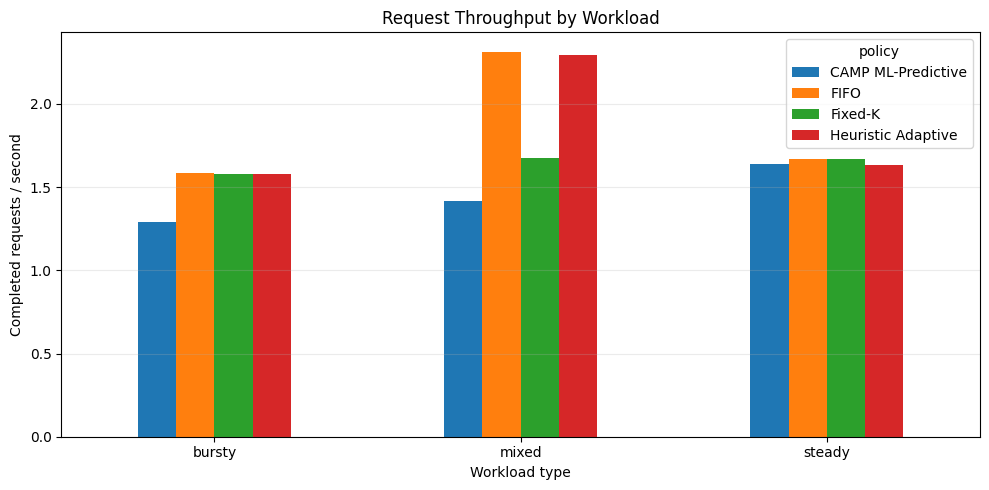

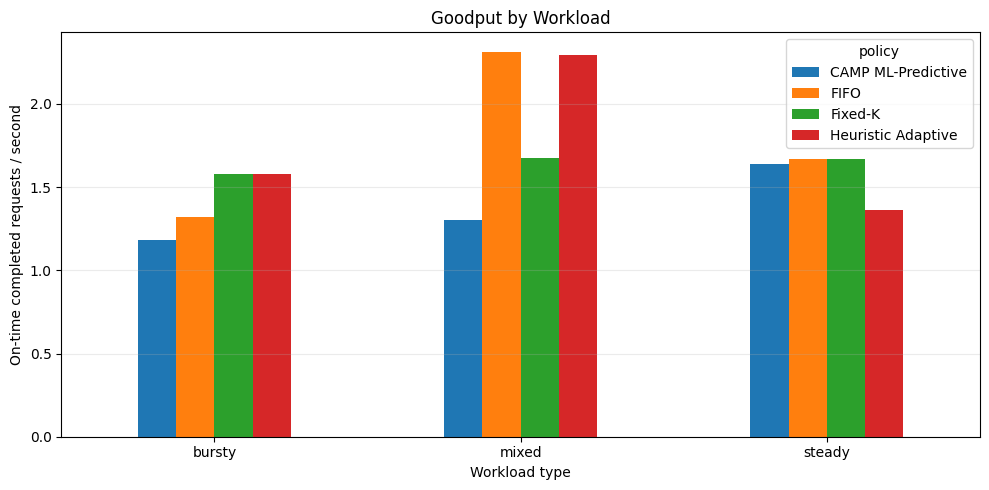

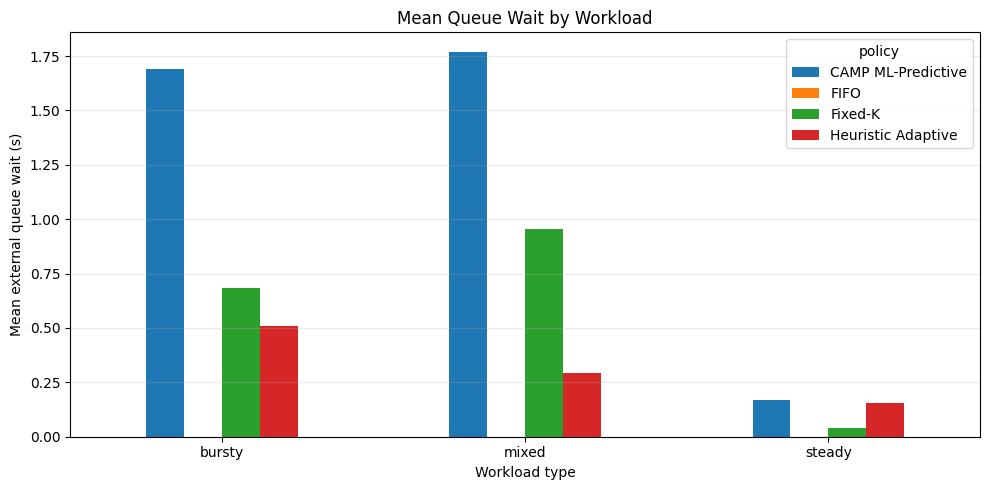

In [20]:
# Compact side-by-side comparison by workload.
comparison_columns = [
    "workload_type", "policy", "success_rate", "mean_queue_wait_s",
    "p95_engine_latency_s", "request_throughput_rps",
    "output_token_throughput_tps", "goodput_rps", "max_queue_wait_s"
]
comparison_df = summary_df[comparison_columns].copy()
display(comparison_df.sort_values(["workload_type", "policy"]).round(4))

# Plot p95 engine latency by workload and policy.
for metric, ylabel, title in [
    ("p95_engine_latency_s", "P95 engine latency (s)", "P95 Engine Latency by Workload"),
    ("request_throughput_rps", "Completed requests / second", "Request Throughput by Workload"),
    ("goodput_rps", "On-time completed requests / second", "Goodput by Workload"),
    ("mean_queue_wait_s", "Mean external queue wait (s)", "Mean Queue Wait by Workload"),
]:
    pivot = summary_df.pivot(index="workload_type", columns="policy", values=metric)
    ax = pivot.plot(kind="bar", figsize=(10, 5))
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.set_xlabel("Workload type")
    ax.grid(axis="y", alpha=0.25)
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

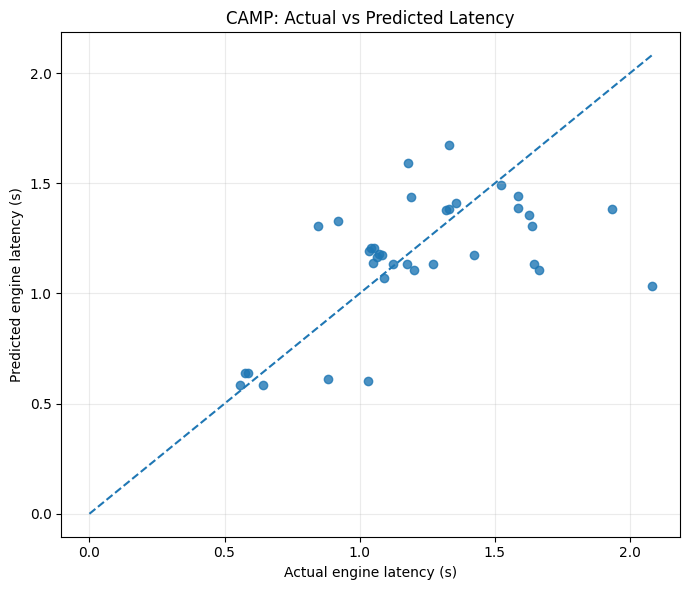

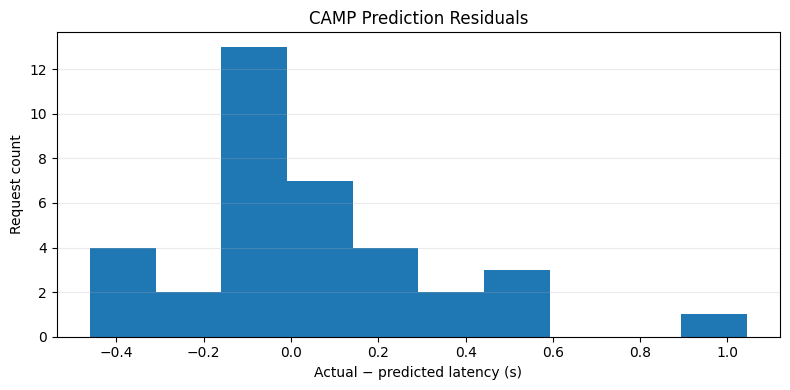

In [21]:
# Request-level prediction diagnostic plot for CAMP.
if len(camp_rows):
    plt.figure(figsize=(7, 6))
    plt.scatter(camp_rows["engine_latency_s"], camp_rows["predicted_engine_latency_s"], alpha=0.8)
    max_value = max(
        float(camp_rows["engine_latency_s"].max()),
        float(camp_rows["predicted_engine_latency_s"].max())
    )
    plt.plot([0, max_value], [0, max_value], linestyle="--")
    plt.xlabel("Actual engine latency (s)")
    plt.ylabel("Predicted engine latency (s)")
    plt.title("CAMP: Actual vs Predicted Latency")
    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(8, 4))
    residual = camp_rows["engine_latency_s"] - camp_rows["predicted_engine_latency_s"]
    plt.hist(residual, bins=10)
    plt.xlabel("Actual − predicted latency (s)")
    plt.ylabel("Request count")
    plt.title("CAMP Prediction Residuals")
    plt.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    plt.show()

## 8. Save results

The following files are the evidence for this experiment. Keep them with the model artifacts from Notebook 02.

In [22]:
OUTPUT_DIR = Path("/content/camp_scheduler_results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Drop monotonic-clock columns from the portable CSV; keep elapsed measurements.
portable_results = results_df.drop(columns=["enqueue_perf", "completion_perf"], errors="ignore")
portable_results.to_csv(OUTPUT_DIR / "camp_scheduler_request_results.csv", index=False)
summary_df.to_csv(OUTPUT_DIR / "camp_scheduler_summary.csv", index=False)
comparison_df.to_csv(OUTPUT_DIR / "camp_scheduler_comparison.csv", index=False)
if len(predictor_report):
    predictor_report.to_csv(OUTPUT_DIR / "camp_predictor_benchmark_metrics.csv", index=False)

run_metadata = {
    "project": "CAMP - Calibration-Aware ML-Predictive Scheduling",
    "model_id": MODEL_ID,
    "gpu": torch.cuda.get_device_name(0),
    "gpu_memory_gib": round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
    "selected_predictor": SELECTED_MODEL_NAME,
    "predictor_features": FEATURES,
    "calibration_residual_margin_s": CALIBRATION_MARGIN_S,
    "pilot_engine_latency_slo_s": SLO_TARGET_S,
    "fixed_k": FIXED_K,
    "adaptive_concurrency": [MIN_ADAPTIVE_K, MAX_ADAPTIVE_K],
    "aging_tau_s": AGING_TAU_S,
    "max_wait_priority_s": MAX_WAIT_PRIORITY_S,
    "benchmark_requests_per_workload": {
        str(k): int(v) for k, v in benchmark_df.groupby("workload_type").size().items()
    },
    "warning": "Small pilot benchmark only; repeat with larger independent traces before making research claims."
}
(OUTPUT_DIR / "camp_scheduler_run_metadata.json").write_text(json.dumps(run_metadata, indent=2))

print("Saved results to:", OUTPUT_DIR)
for file_path in sorted(OUTPUT_DIR.iterdir()):
    print(f"{file_path.name:42s} {file_path.stat().st_size / 1024:8.1f} KB")

Saved results to: /content/camp_scheduler_results
camp_predictor_benchmark_metrics.csv            0.1 KB
camp_scheduler_comparison.csv                   1.8 KB
camp_scheduler_request_results.csv             61.4 KB
camp_scheduler_run_metadata.json                0.9 KB
camp_scheduler_summary.csv                      4.2 KB


In [23]:
# Download experiment evidence to your computer.
from google.colab import files

for filename in [
    "camp_scheduler_request_results.csv",
    "camp_scheduler_summary.csv",
    "camp_scheduler_comparison.csv",
    "camp_scheduler_run_metadata.json",
    "camp_predictor_benchmark_metrics.csv",
]:
    result_path = OUTPUT_DIR / filename
    if result_path.exists():
        files.download(str(result_path))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 9. Interpretation checklist (complete after seeing your actual outputs)

Do not claim CAMP is better just because its prediction model has a lower MAE. Check all of the following:

- Does CAMP reduce p95 engine latency compared with Heuristic Adaptive?
- Does it maintain or improve completion rate and goodput?
- Does output-token throughput change?
- Are long-prompt or long-output requests waiting much longer? Inspect `max_queue_wait_s` and request-level rows.
- How often does the predictor fall back to the heuristic estimate?
- Does calibrated-upper coverage remain close to its intended level on this separate benchmark trace?
- Are results consistent across steady, mixed, and bursty workloads?

**Limitations of the current pilot:** one small benchmark trace per workload type, only 12 requests per workload from Notebook 01, one Colab GPU session, and a pilot SLO derived from the collection dataset. For a research-paper evaluation, expand the traces (for example, 100–500 requests per workload, multiple independent seeds, and repeated runs), preserve held-out trace separation, and report uncertainty intervals. Do not present pilot numbers as publication conclusions.